In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from scipy.stats import chisquare, binomtest
from collections import Counter

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
folder = Path(
    r"C:\Users\lokes\OneDrive\Desktop\Extra\Project\CryptoLabX_group8\classical\Random_Number_Generation"
)

files = {
    "Linux /dev/urandom": folder / "linux_urandom.bin",
    "OpenSSL RAND": folder / "openssl_rand.bin",
    "Windows CNG": folder / "windows_cng.bin"
}

data = {}

for name, filename in files.items():

    raw = filename.read_bytes()

    assert len(raw) >= 1024 * 1024

    data[name] = np.frombuffer(raw, dtype=np.uint8)

    print(name)
    print("File size:", len(raw), "bytes")
    print("Loaded successfully!")
    print()

Linux /dev/urandom
File size: 1048576 bytes
Loaded successfully!

OpenSSL RAND
File size: 1048576 bytes
Loaded successfully!

Windows CNG
File size: 1048576 bytes
Loaded successfully!



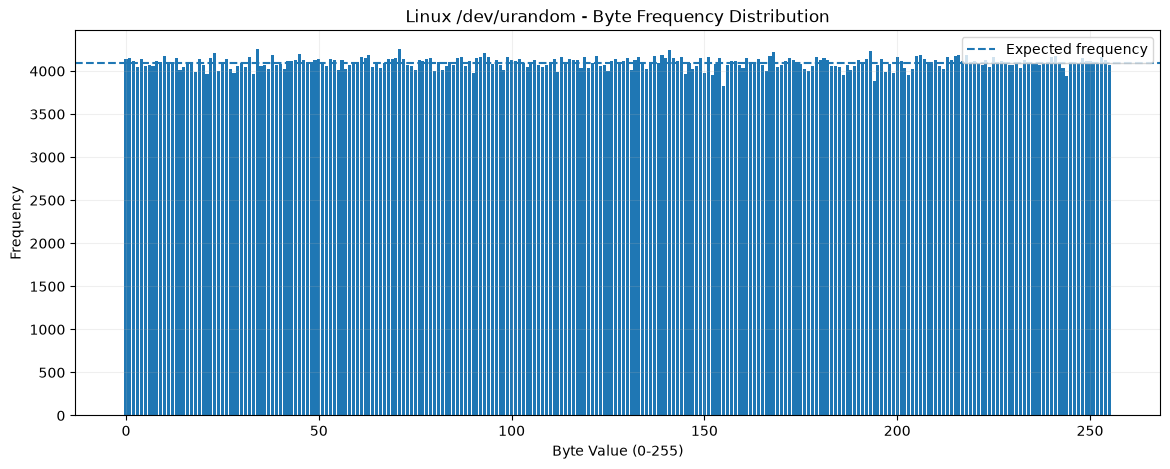

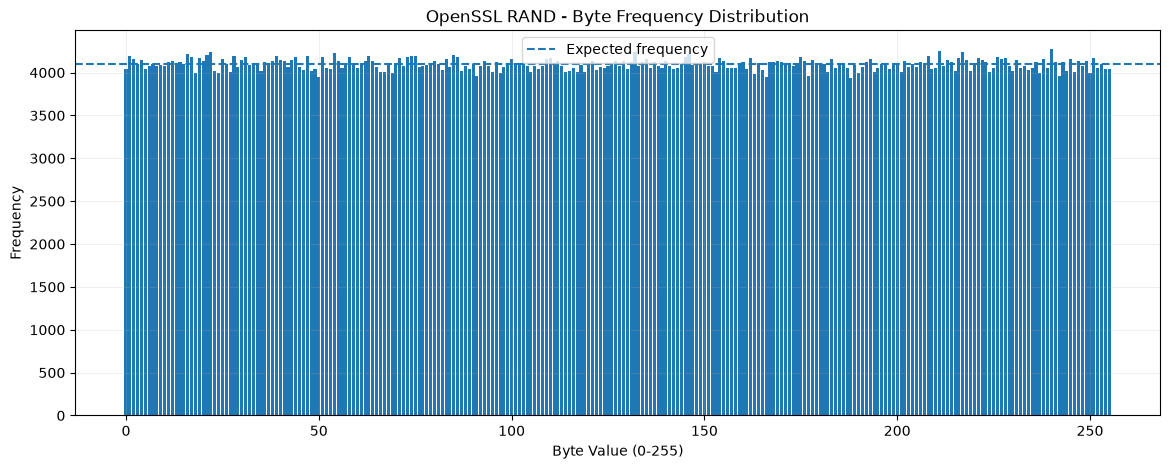

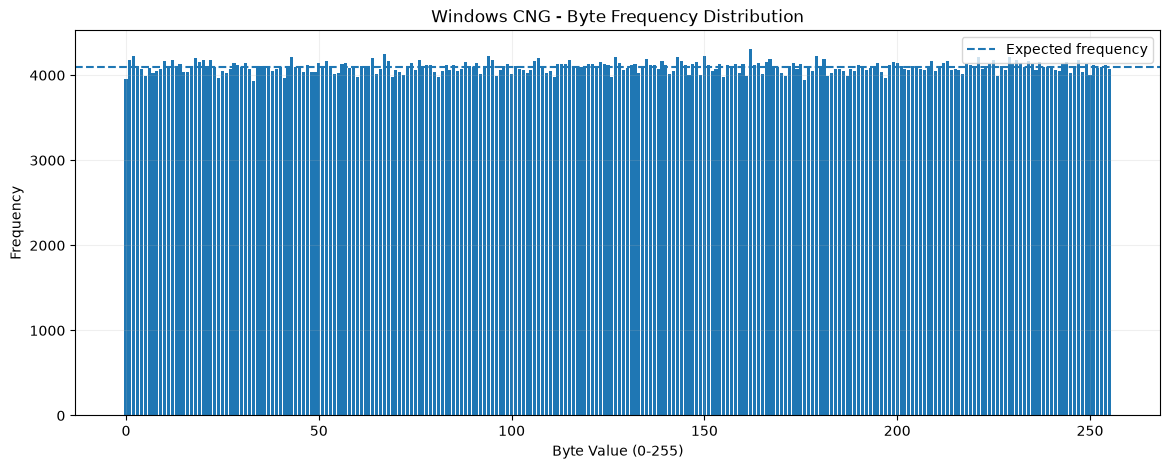

In [3]:
for name, arr in data.items():

    frequencies = np.bincount(arr, minlength=256)

    plt.figure(figsize=(14, 5))

    plt.bar(range(256), frequencies)

    plt.axhline(
        len(arr) / 256,
        linestyle="--",
        label="Expected frequency"
    )

    plt.title(name + " - Byte Frequency Distribution")
    plt.xlabel("Byte Value (0-255)")
    plt.ylabel("Frequency")
    plt.legend()
    plt.grid(alpha=0.2)

    plt.show()

In [4]:
print("===== CHI-SQUARE UNIFORMITY TEST =====\n")

for name, arr in data.items():

    observed = np.bincount(arr, minlength=256)

    expected = np.full(256, len(arr) / 256)

    statistic, p_value = chisquare(
        observed,
        expected
    )

    print(name)
    print("Chi-square statistic:", statistic)
    print("P-value:", p_value)

    if p_value > 0.05:
        print("Result: No significant deviation from uniformity")
    else:
        print("Result: Significant deviation from uniformity")

    print("-" * 50)

===== CHI-SQUARE UNIFORMITY TEST =====

Linux /dev/urandom
Chi-square statistic: 243.22607421875
P-value: 0.6914499284155902
Result: No significant deviation from uniformity
--------------------------------------------------
OpenSSL RAND
Chi-square statistic: 241.30810546875
P-value: 0.7216772587834018
Result: No significant deviation from uniformity
--------------------------------------------------
Windows CNG
Chi-square statistic: 239.15185546875
P-value: 0.7540137573746662
Result: No significant deviation from uniformity
--------------------------------------------------


In [5]:
print("===== BIT DISTRIBUTION TEST =====\n")

for name, arr in data.items():

    bits = np.unpackbits(arr)

    ones = np.sum(bits)
    zeros = len(bits) - ones

    p_value = binomtest(
        int(ones),
        n=len(bits),
        p=0.5
    ).pvalue

    print(name)
    print("Total bits:", len(bits))
    print("Number of zeros:", zeros)
    print("Number of ones:", ones)
    print("Percentage of ones:", ones / len(bits) * 100)
    print("P-value:", p_value)

    print("-" * 50)

===== BIT DISTRIBUTION TEST =====

Linux /dev/urandom
Total bits: 8388608
Number of zeros: 4193508
Number of ones: 4195100
Percentage of ones: 50.00948905944824
P-value: 0.5827860248704045
--------------------------------------------------
OpenSSL RAND
Total bits: 8388608
Number of zeros: 4196214
Number of ones: 4192394
Percentage of ones: 49.9772310256958
P-value: 0.18731136399881498
--------------------------------------------------
Windows CNG
Total bits: 8388608
Number of zeros: 4192684
Number of ones: 4195924
Percentage of ones: 50.01931190490723
P-value: 0.2634304501902743
--------------------------------------------------


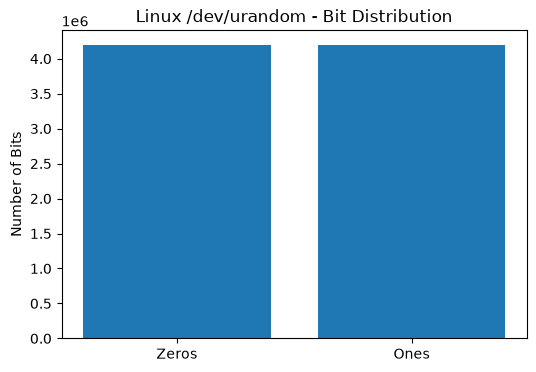

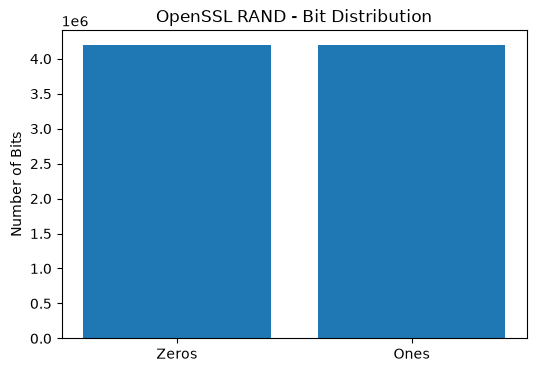

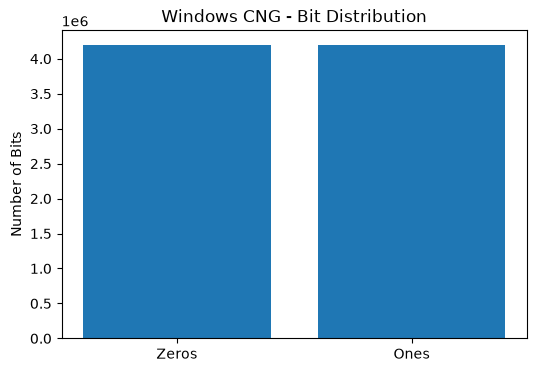

In [6]:
for name, arr in data.items():

    bits = np.unpackbits(arr)

    zeros = np.sum(bits == 0)
    ones = np.sum(bits == 1)

    plt.figure(figsize=(6, 4))

    plt.bar(
        ["Zeros", "Ones"],
        [zeros, ones]
    )

    plt.title(name + " - Bit Distribution")
    plt.ylabel("Number of Bits")

    plt.show()

In [7]:
print("===== REPEATED PATTERN ANALYSIS =====\n")

for name, arr in data.items():

    raw = arr.tobytes()

    print(name)

    for block_size in [4, 8]:

        blocks = [
            raw[i:i + block_size]
            for i in range(0, len(raw) - block_size + 1, block_size)
        ]

        counts = Counter(blocks)

        repeated = sum(
            count - 1
            for count in counts.values()
            if count > 1
        )

        print(f"{block_size}-byte blocks:")
        print("Total blocks:", len(blocks))
        print("Repeated blocks:", repeated)

    print("-" * 50)

===== REPEATED PATTERN ANALYSIS =====

Linux /dev/urandom
4-byte blocks:
Total blocks: 262144
Repeated blocks: 5
8-byte blocks:
Total blocks: 131072
Repeated blocks: 0
--------------------------------------------------
OpenSSL RAND
4-byte blocks:
Total blocks: 262144
Repeated blocks: 4
8-byte blocks:
Total blocks: 131072
Repeated blocks: 0
--------------------------------------------------
Windows CNG
4-byte blocks:
Total blocks: 262144
Repeated blocks: 11
8-byte blocks:
Total blocks: 131072
Repeated blocks: 0
--------------------------------------------------


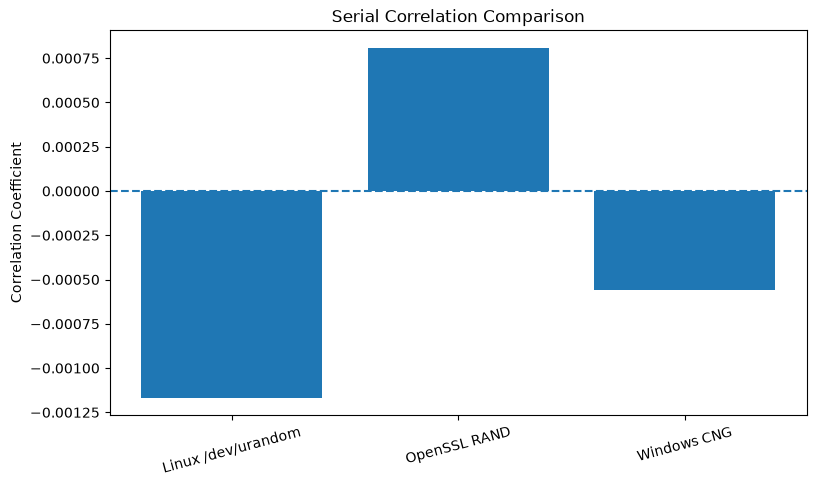

In [8]:
correlations = {}

for name, arr in data.items():

    x = arr.astype(np.float64)

    correlations[name] = np.corrcoef(
        x[:-1],
        x[1:]
    )[0, 1]

plt.figure(figsize=(9, 5))

plt.bar(
    correlations.keys(),
    correlations.values()
)

plt.axhline(0, linestyle="--")

plt.title("Serial Correlation Comparison")
plt.ylabel("Correlation Coefficient")
plt.xticks(rotation=15)

plt.show()

In [9]:
results = []

for name, arr in data.items():

    # Byte frequency
    frequencies = np.bincount(arr, minlength=256)

    chi_stat, chi_p = chisquare(
        frequencies,
        np.full(256, len(arr) / 256)
    )

    # Bit distribution
    bits = np.unpackbits(arr)

    ones = int(np.sum(bits))

    bit_p = binomtest(
        ones,
        n=len(bits),
        p=0.5
    ).pvalue

    # Serial correlation
    x = arr.astype(np.float64)

    correlation = np.corrcoef(
        x[:-1],
        x[1:]
    )[0, 1]

    # Repeated 4-byte blocks
    raw = arr.tobytes()

    blocks = [
        raw[i:i+4]
        for i in range(0, len(raw) - 3, 4)
    ]

    counts = Counter(blocks)

    repeated = sum(
        count - 1
        for count in counts.values()
        if count > 1
    )

    results.append({
        "Generator": name,
        "Chi-square p-value": chi_p,
        "Bit test p-value": bit_p,
        "Serial correlation": correlation,
        "Repeated 4-byte blocks": repeated
    })

comparison = pd.DataFrame(results)

display(comparison)

,Generator,Chi-square p-value,Bit test p-value,Serial correlation,Repeated 4-byte blocks
0,Linux /dev/urandom,0.691450,0.582786,-0.001169,5
1,OpenSSL RAND,0.721677,0.187311,0.000808,4
2,Windows CNG,0.754014,0.263430,-0.000561,11
